# Retriever health and desexing: exploratory results

## Question and scope
How does the proportion of dogs with selected recorded diseases vary across desexing-age categories and intact dogs in this dataset?

This project combines PDF extraction in Python, data preparation in PostgreSQL, descriptive charts and an exploratory chi-square test. Labrador and Golden Retrievers are pooled; individual disease charts are separated by sex. The analysis does not estimate lifespan, establish causation or identify an optimal desexing age.

## Data and preparation
Source: Hart et al. (2014), [research paper](https://doi.org/10.1371/journal.pone.0102241) and [published dataset](https://doi.org/10.6084/m9.figshare.1038819). Field definitions are provided in `dataset/Dataset Key.pdf`.

The original data contain **2,514 dogs**. The SQL standardises equivalent desexing labels and creates an auditable restricted cohort:

- 252 dogs have at least one `invalid` disease entry.
- 37 desexed dogs have a listed diagnosis before surgery.
- Two dogs meet both conditions: **287 distinct dogs are excluded**, leaving **2,227**.
- Missing or unrecognised desexing categories and missing surgery dates in desexed dogs are also checked; they add no exclusions in these files.

`invalid` denotes an out-of-range or unconfirmed diagnosis, not a positive diagnosis. Blank fields mean no recorded diagnosis, not proven absence of disease. Same-day diagnoses remain included because within-day order is unknown.

The exclusion rule applies across all listed diseases: a dog excluded for one disease is absent from every panel. This differs from the source study's disease-specific assignment of diagnoses before surgery to intact exposure.

## Reproduce these results
Run `retriever_desex.sql` and export sections 5b and 5c to the two `_filtered.csv` files below. Then restart this notebook's kernel and run all cells from the project root. The notebook reads CSV exports; it does not query PostgreSQL directly.


## 1. Cohort counts and recorded proportions
Each dog contributes once to the combined outcome, even when multiple diseases are recorded.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

csv_dir = Path("dataset/csv")
counts = pd.read_csv(csv_dir / "disease_counts_by_desexing_group_filtered.csv")
results = pd.read_csv(csv_dir / "disease_percentages_by_sex_filtered.csv")

expected_groups = ["< 6 mo.", "6 - 11 mo.", "1 yr.", "2 - 8 yr.", "intact"]
if counts["desexing_group"].duplicated().any() or set(counts["desexing_group"]) != set(expected_groups):
    raise ValueError("Expected exactly one count row for each of the five categories.")

count_columns = ["recorded_disease", "no_recorded_disease", "total_dogs"]
counts[count_columns] = counts[count_columns].apply(pd.to_numeric, errors="raise")
if counts[count_columns].isna().any().any() or (counts[count_columns] < 0).any().any():
    raise ValueError("Counts must be non-missing and non-negative.")
if (counts[count_columns] % 1 != 0).any().any():
    raise ValueError("Counts must be whole numbers.")
if not (counts["recorded_disease"] + counts["no_recorded_disease"]).eq(counts["total_dogs"]).all():
    raise ValueError("Outcome counts do not add to group totals.")

counts = counts.set_index("desexing_group").loc[expected_groups].reset_index()
if counts["total_dogs"].sum() != 2227:
    raise ValueError("Cohort size changed; review the documented exclusions and findings.")

summary = counts.copy()
summary["recorded_disease_pct"] = (
    100 * summary["recorded_disease"] / summary["total_dogs"]
).round(2)
display(summary)


,desexing_group,recorded_disease,no_recorded_disease,total_dogs,recorded_disease_pct
0,< 6 mo.,60,188,248,24.19
1,6 - 11 mo.,65,270,335,19.40
2,1 yr.,12,141,153,7.84
3,2 - 8 yr.,28,274,302,9.27
4,intact,100,1089,1189,8.41


The observed percentages range from **7.84%** in the one-year category to **24.19%** in the under-six-month category. The intact group is **8.41%**. These are descriptive proportions, not annual incidence or lifetime risks.

## 2. Individual diseases by sex
Percentages use the retained dogs in each sex/category as denominators. Scales match between sexes within a disease, but differ between diseases. Male MC and PYO outcomes were not included in the source tables. The figure is saved to `outputs/figures/disease_by_desexing_age_and_sex_filtered.png`.

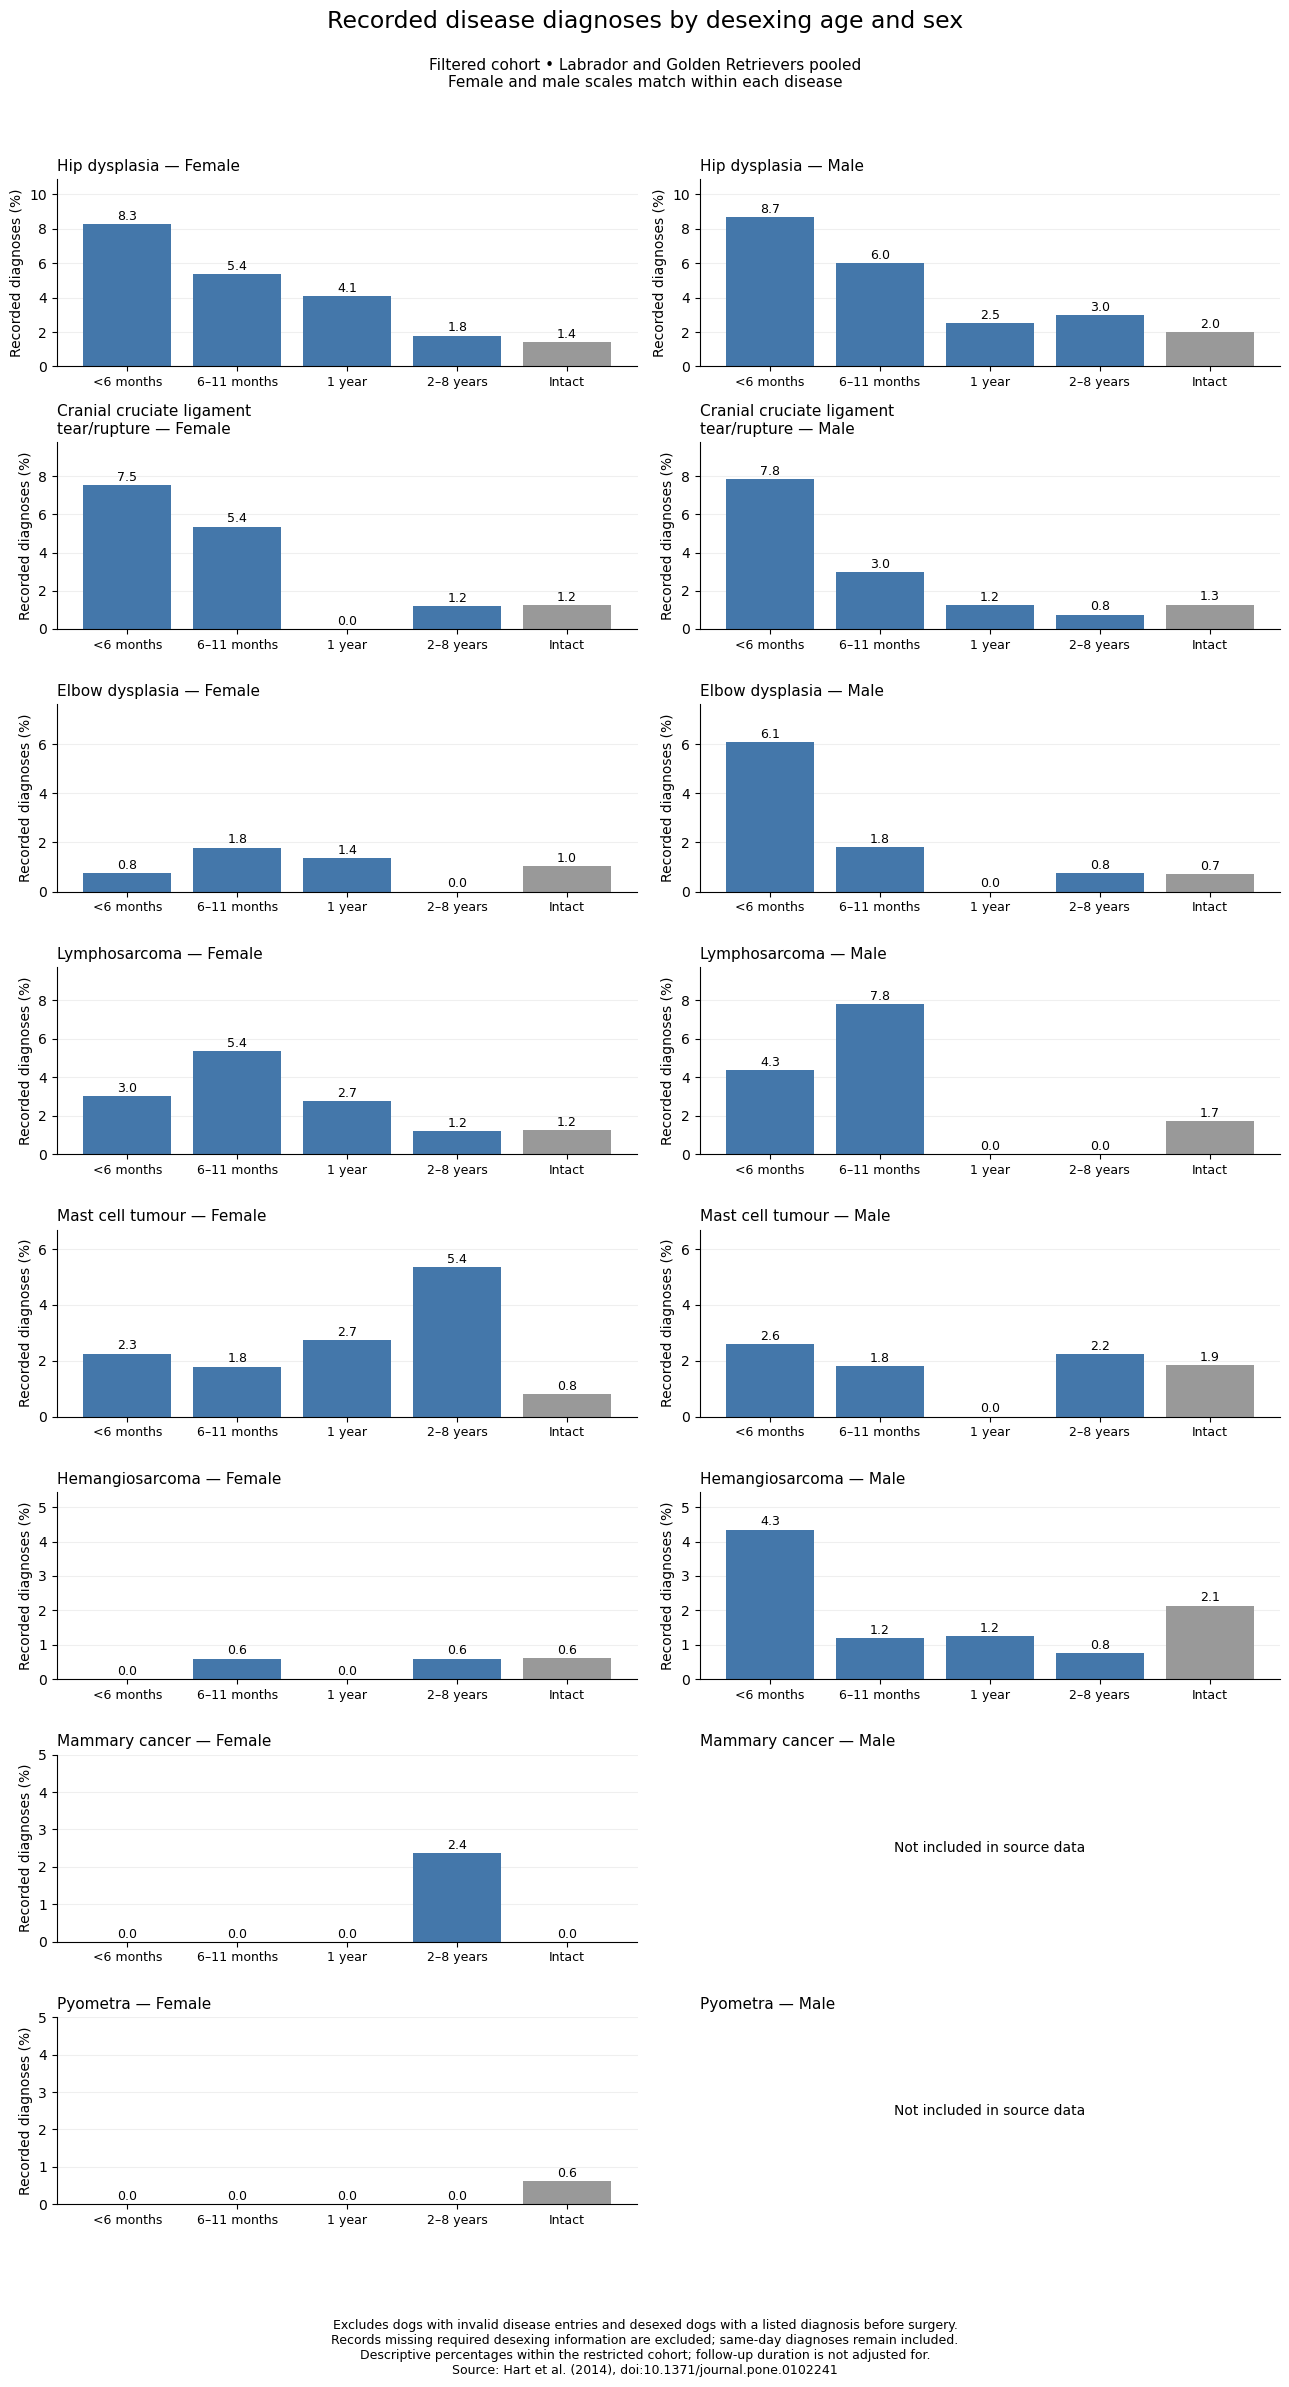

In [2]:
value_columns = [
    "Under 6 months (%)",
    "6–11 months (%)",
    "1 year (%)",
    "2–8 years (%)",
    "Intact (%)"
]

category_labels = [
    "<6 months", "6–11 months", "1 year", "2–8 years", "Intact"
]

disease_names = {
    "HD": "Hip dysplasia",
    "CCL": "Cranial cruciate ligament\ntear/rupture",
    "ED": "Elbow dysplasia",
    "LSA": "Lymphosarcoma",
    "MCT": "Mast cell tumour",
    "HSA": "Hemangiosarcoma",
    "MC": "Mammary cancer",
    "PYO": "Pyometra"
}

colours = ["#4477AA"] * 4 + ["#999999"]

results[value_columns] = results[value_columns].apply(
    pd.to_numeric, errors="raise"
)

if results.duplicated(["sex", "disease"]).any():
    raise ValueError("Expected only one row per sex and disease.")

fig, axes = plt.subplots(
    len(disease_names), 2,
    figsize=(13, 24),
    sharex=True
)

for row, (disease, disease_name) in enumerate(disease_names.items()):
    # Match female and male scales within each disease.
    disease_values = results.loc[
        results["disease"].eq(disease), value_columns
    ]
    maximum = disease_values.max().max()
    upper_limit = max(5, maximum * 1.25) if pd.notna(maximum) else 5

    for col, (sex, label) in enumerate([
        ("f", "Female"),
        ("m", "Male")
    ]):
        ax = axes[row, col]

        ax.set_title(
            f"{disease_name} — {label}",
            loc="left",
            fontsize=11
        )

        # These outcomes were not collected in the male source tables.
        if sex == "m" and disease in ("MC", "PYO"):
            ax.text(
                0.5, 0.5,
                "Not included in source data",
                ha="center",
                va="center",
                transform=ax.transAxes
            )
            ax.set_axis_off()
            continue

        subset = results[
            results["disease"].eq(disease)
            & results["sex"].eq(sex)
        ]

        if subset.empty:
            raise ValueError(f"Missing results for {disease}, sex={sex}")

        values = subset.iloc[0][value_columns].astype(float)

        bars = ax.bar(
            range(len(category_labels)),
            values,
            color=colours
        )

        # Display missing percentages as N/A, rather than zero.
        for bar, value in zip(bars, values):
            if pd.isna(value):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    upper_limit * 0.03,
                    "N/A",
                    ha="center",
                    fontsize=9
                )
            else:
                ax.annotate(
                    f"{value:.1f}",
                    (bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9
                )

        ax.set_ylim(0, upper_limit)
        ax.set_xticks(range(len(category_labels)), category_labels)
        ax.tick_params(axis="x", labelbottom=True, labelsize=9)
        ax.set_ylabel("Recorded diagnoses (%)")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Recorded disease diagnoses by desexing age and sex",
    fontsize=17,
    y=0.995
)

fig.text(
    0.5, 0.975,
    "Filtered cohort • Labrador and Golden Retrievers pooled\n"
    "Female and male scales match within each disease",
    ha="center",
    fontsize=11,
    va="top"
)

fig.text(
    0.5, 0.01,
    "Excludes dogs with invalid disease entries and desexed dogs with a listed diagnosis before surgery.\n"
    "Records missing required desexing information are excluded; same-day diagnoses remain included.\n"
    "Descriptive percentages within the restricted cohort; follow-up duration is not adjusted for.\n"
    "Source: Hart et al. (2014), doi:10.1371/journal.pone.0102241",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.065, 1, 0.955])

output_dir = Path("outputs/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "disease_by_desexing_age_and_sex_filtered.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Exploratory chi-square test
**Null hypothesis:** the proportion with any listed recorded disease is equal across the five categories. Only the two outcome-count columns enter the test. An overlapping “All desexed” row is not included. Expected counts are hypothetical counts under the null, not observed diagnoses.

In [3]:
# Only the two outcome columns enter the test—not total_dogs.
observed = counts.set_index("desexing_group")[
    ["recorded_disease", "no_recorded_disease"]
]

chi2, p_value, dof, expected = chi2_contingency(
    observed,
    correction=False
)

print(f"Chi-square: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6g}")
print(f"All expected counts ≥ 5: {(expected >= 5).all()}")

display(pd.DataFrame(
    expected,
    index=observed.index,
    columns=observed.columns
).round(2))

Chi-square: 71.944
Degrees of freedom: 4
P-value: 8.81798e-15
All expected counts ≥ 5: True


,recorded_disease,no_recorded_disease
desexing_group,,
< 6 mo.,29.51,218.49
6 - 11 mo.,39.86,295.14
1 yr.,18.21,134.79
2 - 8 yr.,35.94,266.06
intact,141.48,1047.52


The test gives **χ²(4, N = 2,227) = 71.94, p ≈ 8.82 × 10⁻¹⁵**. All expected counts exceed five, satisfying this count-size check for the approximation. This does not establish independence, eliminate confounding or validate causal claims.

## Interpretation and limitations

The overall test indicates an association between category and recorded disease occurrence in this **restricted sample**. It does not test each pair separately or show that any particular desexing age causes disease.

- **Unequal observation:** dogs with longer follow-up have more opportunity for diagnosis. Observation length is not adjusted here.
- **Selection from exclusions:** desexed dogs must be free of the listed recorded diseases before surgery to remain included, while intact dogs have no equivalent surgery checkpoint. Later-surgery groups therefore face different selection conditions.
- **Pooled populations:** breed and sex distributions can differ between categories. The combined outcome includes female-only source fields for mammary cancer and pyometra.
- **Composite outcome:** one flag combines distinct diseases; individual charts are descriptive, with no disease-specific hypothesis tests or uncertainty intervals.
- **Source limitations:** these are retrospective hospital records, not a random sample of all retrievers. Missing entries do not guarantee absence of disease.

The appropriate conclusion is that recorded proportions differ in the selected data, with substantial limitations on interpretation. A stronger follow-up would analyse individual diseases by breed and sex, using observation time and desexing as a time-varying exposure. That is outside this project's scope.

## Data-quality lesson
An initial nonblank-field rule counted the literal value `invalid` as a diagnosis. Consulting the dataset key exposed the error. The final outputs here use the corrected, explicitly filtered cohort; the earlier unfiltered exports and chart are superseded and should not be interpreted as findings.
